In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns

antenne = gpd.read_file("projet_telecom.gpkg", layer="antenne")
provinces = gpd.read_file("projet_telecom.gpkg", layer="provinces")
population = gpd.read_file("projet_telecom.gpkg", layer="population")

In [15]:
# Nombre d'antenne par type réseau
print("Type d'antenne :\n  ",antenne["radio"].value_counts())

#Statistiques sur la portée
print("Statitistique : \n" ,antenne["range"].describe())

Type d'antenne :
   radio
GSM     18022
LTE       268
UMTS       21
Name: count, dtype: int64
Statitistique : 
 count    18311.000000
mean      2831.814483
std       3534.415271
min        500.000000
25%       1000.000000
50%       1000.000000
75%       3374.000000
max      33616.000000
Name: range, dtype: float64


In [17]:
# Population Total
print("Population Total : \n ",population["Z"].sum())

# Statitistiques de la population par carré de 1km²
print(population["Z"].describe())

# Les 10 zones les plus peuplées
print(population.sort_values(by="Z", ascending=False).head(10))

Population Total : 
  133851524.7536695
count    2.703157e+06
mean     4.951674e+01
std      4.935134e+02
min      0.000000e+00
25%      3.403234e+00
50%      1.003035e+01
75%      2.984018e+01
max      1.241484e+05
Name: Z, dtype: float64
                     Z                   geometry
1621386  124148.359375  POINT (15.27792 -4.34625)
1623089  112283.796875  POINT (15.28625 -4.35458)
1626503  104755.382812  POINT (15.29458 -4.37125)
1626504   96018.289062  POINT (15.30292 -4.37125)
1619685   94217.445312  POINT (15.27792 -4.33792)
1624795   87381.703125  POINT (15.29458 -4.36292)
1629929   86766.648438  POINT (15.34458 -4.38792)
1626505   81413.578125  POINT (15.31125 -4.37125)
1624794   78929.007812  POINT (15.28625 -4.36292)
1626502   77491.492188  POINT (15.28625 -4.37125)


In [19]:
print("Nombre de Provinces :", len(provinces))
print(provinces[["NAME_1","geometry"]].head())

Nombre de Provinces : 26
         NAME_1                                           geometry
0      Bas-Uele  MULTIPOLYGON (((23.54289 2.44556, 23.53645 2.4...
1      Équateur  MULTIPOLYGON (((17.11355 -1.78642, 17.10765 -1...
2  Haut-Katanga  MULTIPOLYGON (((28.52324 -11.88198, 28.53324 -...
3   Haut-Lomami  MULTIPOLYGON (((25.49803 -9.49573, 25.4987 -9....
4     Haut-Uele  MULTIPOLYGON (((28.3139 2.33613, 28.31679 2.31...


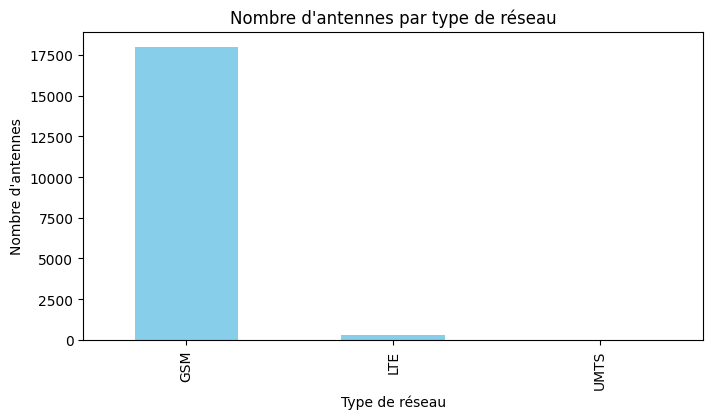

In [ ]:
# Graphique 1 : Répartition des technologies
plt.figure(figsize=(8, 4))
antenne['radio'].value_counts().plot(kind='bar', color='skyblue')
plt.title("Nombre d'antennes par type de réseau")
plt.xlabel("Type de réseau")
plt.ylabel("Nombre d'antennes")
plt.show()



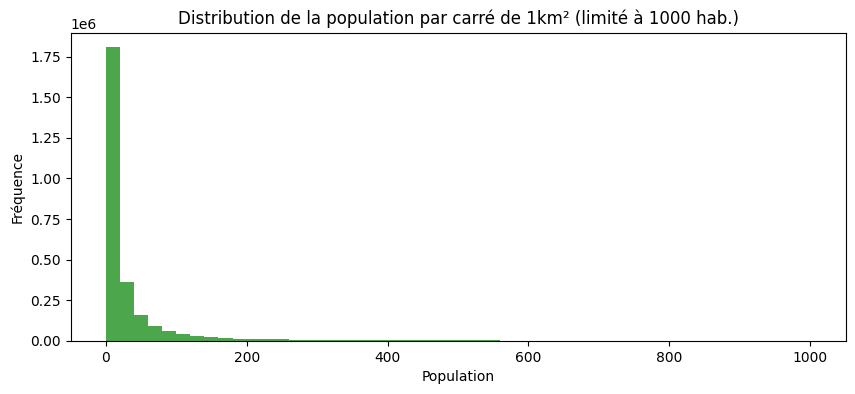

In [ ]:
# Graphique 2 : Distribution de la population (Histogramme)

# Note : Comme la population est très concentrée, on limite l'axe des X pour mieux voir
plt.figure(figsize=(10, 4))
plt.hist(population['Z'], bins=50, range=(0, 1000), color='green', alpha=0.7)
plt.title("Distribution de la population par carré de 1km² (limité à 1000 hab.)")
plt.xlabel("Population")
plt.ylabel("Fréquence")
plt.show()

In [23]:
print("verification de systeme de projection : ",antenne.crs)
print("verification de systeme de projection : ",provinces.crs)

verification de systeme de projection :  EPSG:4326
verification de systeme de projection :  EPSG:4326
